# Exercise 3: Deep versus wide networks

Feed-forward networks on the noisy-XOR problem using PyTorch.

## Setup
Import libraries

In [1]:
import copy, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

All training settings live in `CFG`

In [2]:
CFG = dict(n_train=500,n_val=500, n_test=1000, s=0.1,epochs=200, batch_size=32, lr=0.01, repeats=10)

Select device

In [3]:
cuda_available = torch.cuda.is_available()
mps_available = torch.backends.mps.is_available()
device = os.environ.get("DEVICE") or ("cuda" if cuda_available else "mps" if mps_available else "cpu")
print("device:", device)

device: mps


Helper method for seed setting

In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

Create folder for results

In [5]:
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## Data
Each point is a random cluster centre plus Gaussian noise, and the label is the XOR of the centre coordinates.

In [6]:
class NoisyXOR(TensorDataset):
    def __init__(self, n, s, seed):
        gen = torch.Generator().manual_seed(seed)
        centers = torch.randint(0, 2, (n, 2), generator=gen).float()
        X = centers + s * torch.randn(n, 2, generator=gen)
        y = (centers[:, 0] != centers[:, 1]).float().unsqueeze(1)
        super().__init__(X, y)

## Model
`depth` hidden tanh layers of size `width`, and a single output logit (the sigmoid is inside the loss).

In [ ]:
class Net(nn.Module):
    def __init__(self, depth, width):
        super().__init__()
        layers, d_in = [], 2
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.Tanh()]
            d_in = width
        layers += [nn.Linear(d_in, 1), nn.Identity()]
        self.model = nn.Sequential(*layers)

    def forward(self, x): return self.model(x)

def count_params(model): return sum(p.numel() for p in model.parameters())

print(Net(1, 3))

Net(
  (model): Sequential(
    (0): Linear(in_features=2, out_features=3, bias=True)
    (1): Tanh()
    (2): Linear(in_features=3, out_features=1, bias=True)
    (3): Identity()
  )
)


## Training and evaluation
Mini-batch training with `DataLoader` and Adam, logging the train and validation loss after every epoch.

In [8]:
@torch.no_grad()
def evaluate(model, ds):
    model.eval()
    X, y = (t.to(device) for t in ds.tensors)
    logits = model(X)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, y).item()
    acc = ((logits > 0).float() == y).float().mean().item()

    return loss, acc

def snapshot(model): return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def train(model, train_ds, val_ds, cfg=CFG, snapshot_every=None):
    loader = DataLoader(train_ds, batch_size=cfg["batch_size"], shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    loss_fn = nn.BCEWithLogitsLoss()
    hist = {"train_loss": [], "val_loss": [], "snapshots": []}

    if snapshot_every: hist["snapshots"].append(snapshot(model))

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            loss = loss_fn(model(X), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        hist["train_loss"].append(evaluate(model, train_ds)[0])
        hist["val_loss"].append(evaluate(model, val_ds)[0])
    
        if snapshot_every and epoch % snapshot_every == 0: hist["snapshots"].append(snapshot(model))
            
    return hist

## Plot helpers
A decision boundary is where the logit is 0, i.e. where the model predicts 50/50.

In [9]:
LIM = (-0.5, 1.5)

def plot_data(ax, ds, title):
    X, y = ds.tensors
    y = y.squeeze()
    for c, col in [(0, "tab:blue"), (1, "tab:orange")]:
        ax.scatter(*X[y == c].T, c=col, edgecolor="k", s=18, label=f"Class {c}", zorder=3)

    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=LIM, ylim=LIM, aspect="equal")

@torch.no_grad()
def plot_boundary(ax, model, n=150):
    g = torch.linspace(*LIM, n)
    xx, yy = torch.meshgrid(g, g, indexing="xy")
    grid = torch.stack([xx.ravel(), yy.ravel()], 1).to(device)
    z = model.eval()(grid).cpu().reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[-1e9, 0, 1e9], colors=["tab:blue", "tab:orange"], alpha=0.15)
    ax.contour(xx, yy, z, levels=[0], colors="k", linewidths=2)
    ax.plot([], [], "k-", lw=2, label="output boundary")         # legend entry

def plot_hidden_lines(ax, W, b):
    """Draw w1*x1 + w2*x2 + b = 0 for each first-layer unit (where tanh crosses 0)."""
    t = np.linspace(*LIM, 2)
    for i, ((w1, w2), bi) in enumerate(zip(W.tolist(), b.tolist())):
        if abs(w2) > abs(w1):
            ax.plot(t, -(w1 * t + bi) / w2, "--", lw=1.5, label=f"hidden {i + 1}")
        else:
            ax.plot(-(w2 * t + bi) / w1, t, "--", lw=1.5, label=f"hidden {i + 1}")

## 1. Train the 2-3-1 network
Training and validation sets come from the same source but use different seeds.

validation loss = 0.0032, accuracy = 1.000


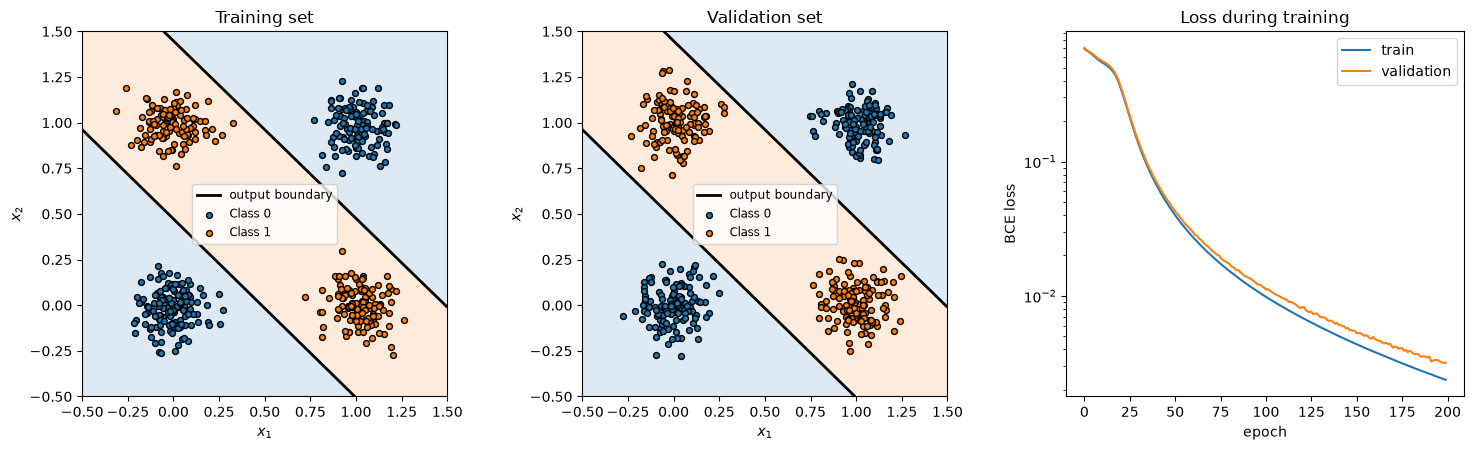

In [10]:
set_seed(0)
train_ds = NoisyXOR(CFG["n_train"], CFG["s"], seed=1)
val_ds = NoisyXOR(CFG["n_val"], CFG["s"], seed=2)

model = Net(1, 3).to(device)
hist = train(model, train_ds, val_ds)
print("validation loss = %.4f, accuracy = %.3f" % evaluate(model, val_ds))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, ds, name in [(axes[0], train_ds, "Training set"), (axes[1], val_ds, "Validation set")]:
    plot_boundary(ax, model)
    plot_data(ax, ds, name)
    ax.legend(loc="center", fontsize="small")

axes[2].plot(hist["train_loss"], label="train")
axes[2].plot(hist["val_loss"], label="validation")
axes[2].set(title="Loss during training", xlabel="epoch", ylabel="BCE loss", yscale="log")
axes[2].legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/q1_train_val.png", dpi=150)

plt.show()

### 1. a) Which binary cross-entropy loss?
PyTorch has `nn.BCELoss`, which expects probabilities (so the model must end with a sigmoid), and `nn.BCEWithLogitsLoss`, which takes the raw output and applies the sigmoid itself.
We use `BCEWithLogitsLoss` as it matches the `Identity` output layer and is numerically more stable, because combining the sigmoid and the log avoids `log(0)` when outputs saturate.

## 2. Depth versus width
Every depth/width combination is trained `repeats` times with new data and weights, then scored on a new test set.

In [11]:
rows = []
for depth in range(4):
    for width in ([0] if depth == 0 else [1, 2, 3]):
        for rep in range(CFG["repeats"]):
            seed = 100 * rep
            set_seed(seed)
            tr = NoisyXOR(CFG["n_train"], CFG["s"], seed=seed + 1)
            va = NoisyXOR(CFG["n_val"], CFG["s"], seed=seed + 2)
            te = NoisyXOR(CFG["n_test"], CFG["s"], seed=seed + 3)

            model = Net(depth, width).to(device)
            train(model, tr, va)
            loss, acc = evaluate(model, te)

            sample = dict(depth=depth, width=width, rep=rep, n_params=count_params(model), test_loss=loss, test_acc=acc)
            rows.append(sample)

df = pd.DataFrame(rows)
summary = df.groupby(["depth", "width"]).agg(
    n_params=("n_params", "first"),
    loss_mean=("test_loss", "mean"), 
    loss_std=("test_loss", "std"),
    acc_mean=("test_acc", "mean"), 
    acc_std=("test_acc", "std")
)
summary.round(3)

n_params  loss_mean  loss_std  acc_mean  acc_std
depth width                                                  
0     0             3      0.696     0.002     0.482    0.155
1     1             5      0.485     0.018     0.748    0.020
      2             9      0.121     0.192     0.924    0.122
      3            13      0.037     0.111     0.974    0.082
2     1             7      0.476     0.014     0.753    0.014
      2            15      0.197     0.211     0.880    0.126
      3            25      0.001     0.001     1.000    0.000
3     1             9      0.488     0.013     0.741    0.012
      2            21      0.273     0.237     0.852    0.127
      3            37      0.051     0.156     0.974    0.082

Depth 0 (logistic regression) is drawn as the shared starting point of every width line.

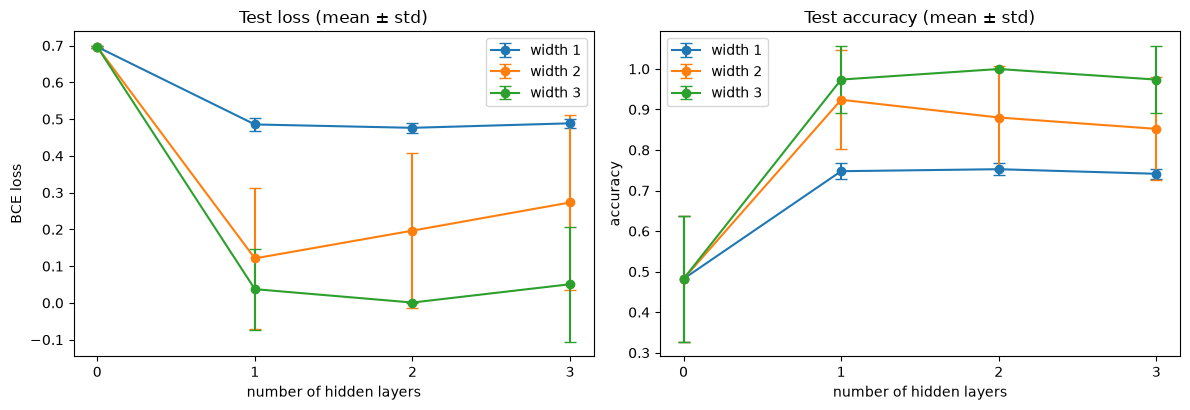

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for width in [1, 2, 3]:
    s = summary[(summary.index.get_level_values("width") == width) | (summary.index.get_level_values("depth") == 0)]
    depths = s.index.get_level_values("depth")
    axes[0].errorbar(depths, s.loss_mean, s.loss_std, marker="o", capsize=4, label=f"width {width}")
    axes[1].errorbar(depths, s.acc_mean, s.acc_std, marker="o", capsize=4, label=f"width {width}")

axes[0].set(title="Test loss (mean ± std)", xlabel="number of hidden layers", ylabel="BCE loss")
axes[1].set(title="Test accuracy (mean ± std)", xlabel="number of hidden layers", ylabel="accuracy")
for ax in axes:
    ax.set_xticks(range(4))
    ax.legend()

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/q2_grid.png", dpi=150)

plt.show()

## 3. Number of parameters
Depth 0 is logistic regression (3 parameters, width unused). A network with $d \ge 1$ hidden layers of width $w$ has $3w + (d-1)(w^2+w) + (w+1)$ parameters.

In [13]:
formula = lambda d, w: 3 if d == 0 else 3 * w + (d - 1) * (w * w + w) + (w + 1)
assert all(formula(d, w) == p for (d, w), p in summary.n_params.items())
pd.DataFrame(
    {f"width {w}": [formula(d, w) for d in range(4)] for w in [1, 2, 3]}, 
    index=pd.Index(range(4), name="hidden layers")
)

,width 1,width 2,width 3
hidden layers,,,
0,3,3,3
1,5,9,13
2,7,15,25
3,9,21,37


### Interpretation

Width matter the most as it has the highest affect in the accuracy and it cannot be compensated with depth. The plots show that by increasing the width the network is able to learn better (75% acc @ width=1 vs ~100% acc @ width=3). However, the sole affect of depth is shown to be minimal or even negative in certain situations and therefore, can be ruled out as an contributing factor. As a conclusion, more parameters only help when they come from width.

## Q4: Decision boundaries of the 2-2-1 network during training
A 2-unit net sometimes gets stuck in a bad solution, so we take the first seed that reaches at least 95 % validation accuracy.

In [14]:
for seed in range(20):
    set_seed(seed)
    model = Net(1, 2).to(device)
    hist = train(model, train_ds, val_ds, snapshot_every=1)
    val_loss, val_acc = evaluate(model, val_ds)
    print(f"seed {seed}: validation loss = {val_loss:.4f}, accuracy = {val_acc:.3f}")
    if val_acc >= 0.95: break

snaps = hist["snapshots"]

def draw_frame(ax, epoch):
    ax.clear()
    model.load_state_dict(snaps[epoch])
    plot_boundary(ax, model)
    plot_hidden_lines(ax, snaps[epoch]["model.0.weight"], snaps[epoch]["model.0.bias"])
    plot_data(ax, train_ds, f"Epoch {epoch}")

seed 0: validation loss = 0.0037, accuracy = 1.000


Four snapshots for the report.

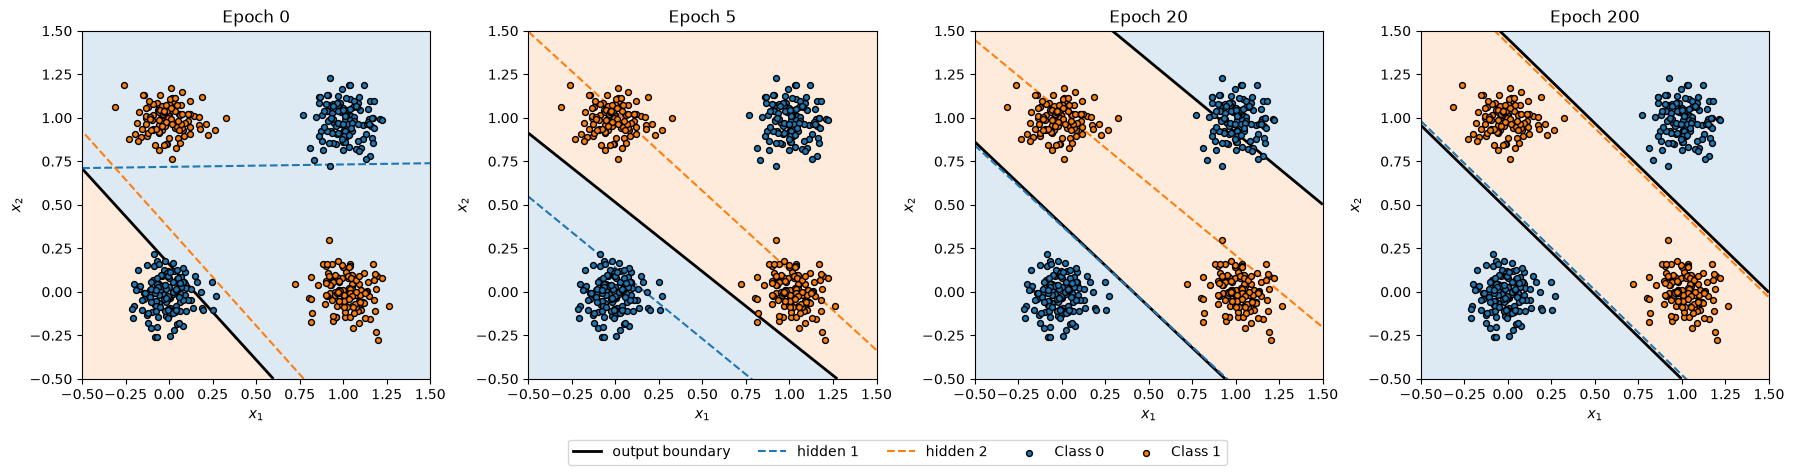

In [15]:
epochs_to_show = [0, 5, 20, len(snaps) - 1]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, e in zip(axes, epochs_to_show):
    draw_frame(ax, e)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(f"{FIG_DIR}/q4_snapshots.png", dpi=150)
plt.show()

The movie uses every 2nd epoch to keep the GIF small.

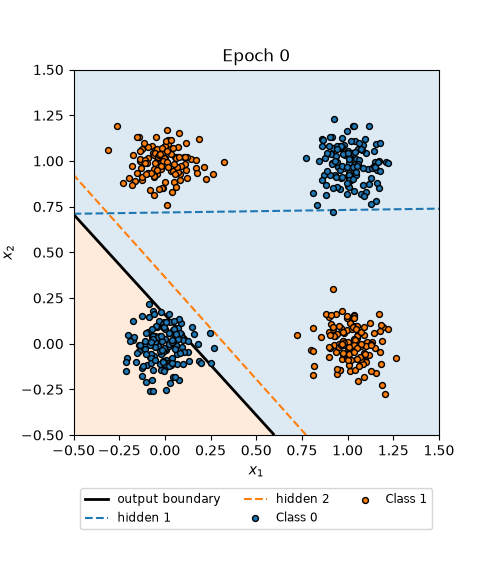

In [12]:
fig, ax = plt.subplots(figsize=(5, 5.8))
frames = list(range(0, len(snaps), 2))

def movie_frame(epoch):
    draw_frame(ax, epoch)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize="small")

fig.subplots_adjust(bottom=0.25)
anim = FuncAnimation(fig, movie_frame, frames=frames)
anim.save(f"{FIG_DIR}/xor_boundaries.gif", writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=f"{FIG_DIR}/xor_boundaries.gif"))